In [6]:
import pandas as pd           # data cleaning, preporcessing, transformation
import numpy as np            # numerical calculations, linear algebra
import matplotlib.pyplot as plt  # visualization
import seaborn as sns 

#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df.
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart.
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City.

</pre>


In [7]:
ca = pd.read_csv('cust_activity.csv')

In [8]:
cb = pd.read_csv('cust_bio.csv')

In [9]:
cs= pd.read_csv('cust_sub.csv')

In [10]:
sp = pd.read_csv('sp.csv')

In [11]:
orders = pd.read_csv('orders (2).csv')

In [12]:
print(ca.shape)
print(orders.shape)
print(cs.shape)
print(cb.shape)
print(sp.shape)

(7500, 3)
(127, 4)
(51, 3)
(478, 3)
(6, 5)


In [13]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(sp.columns)
print(orders.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')


In [14]:
ca.dtypes

Cust_ID     str
Activity    str
Date        str
dtype: object

In [15]:
cb.dtypes

Cust_ID      str
City         str
Age        int64
dtype: object

In [16]:
cs.dtypes

Cust_ID          str
Plan_Var_ID      str
Purchase_Date    str
dtype: object

In [17]:
sp.dtypes

Plan_Var_ID        str
Plan_ID            str
Plan_name          str
Price          float64
Duration           str
dtype: object

In [18]:
orders.dtypes

Order_id            str
Cust_ID             str
Amount          float64
Payment_mode        str
dtype: object

In [19]:
print(ca.isnull().sum())
print(cb.isnull().sum())
print(cs.isnull().sum())
print(sp.isnull().sum())
print(orders.isnull().sum())

Cust_ID     0
Activity    0
Date        0
dtype: int64
Cust_ID    0
City       0
Age        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64


In [20]:
# by using loop
for i in (ca,cs,cb,sp,orders):
    print(i.isnull().sum())

Cust_ID     0
Activity    0
Date        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Cust_ID    0
City       0
Age        0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64


In [21]:
def check_dup(data):
    dup = data.duplicated().sum()
    if dup > 0:
        print(dup)
    else:
        print('No Duplicates')

In [22]:
for i in (ca,cs,cb,sp,orders):
    check_dup(i)

No Duplicates
No Duplicates
No Duplicates
No Duplicates
No Duplicates


In [23]:
import plotly.express as px

#### 2) Find Count of Customers from each city and represent it on bar chart.


In [24]:
q2 = cb['City'].value_counts().reset_index()  # ye data frame mai convert krne ke liye use hota hai aur plotly mai dataframe krna zruri hai
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


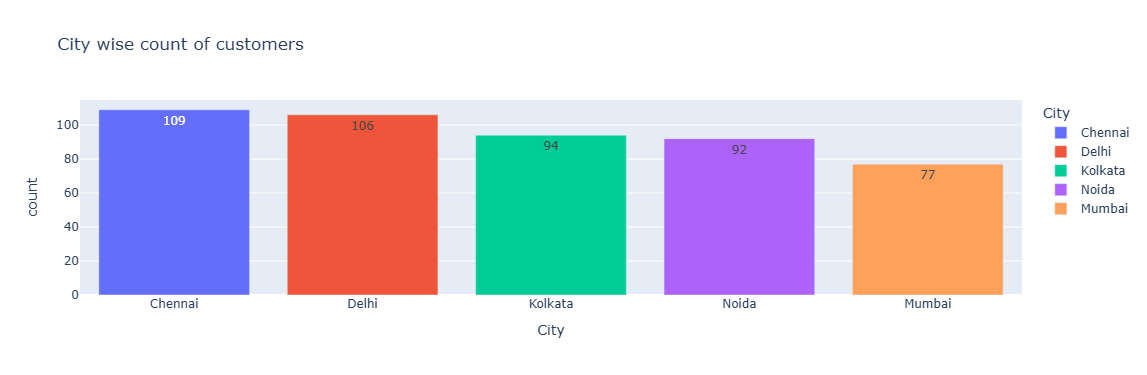

In [25]:
fig = px.bar(data_frame = q2 , x = 'City', y = 'count',title = 'City wise count of customers',color = 'City',
             text = 'count')
fig.show()

#### 3) Find Range Age wise count of cutsomers, represent it on pie chart.


In [26]:
cb['Age'].describe()

count    478.000000
mean      28.740586
std        5.376756
min       20.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       37.000000
Name: Age, dtype: float64

In [27]:
cb['Age_Range'] = pd.cut(cb['Age'], bins=[19,24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [28]:
q3 = cb['Age_Range'].value_counts().reset_index()
q3

,Age_Range,count
0,"(19, 24]",137
1,"(29, 34]",130
2,"(24, 29]",120
3,"(34, 39]",91


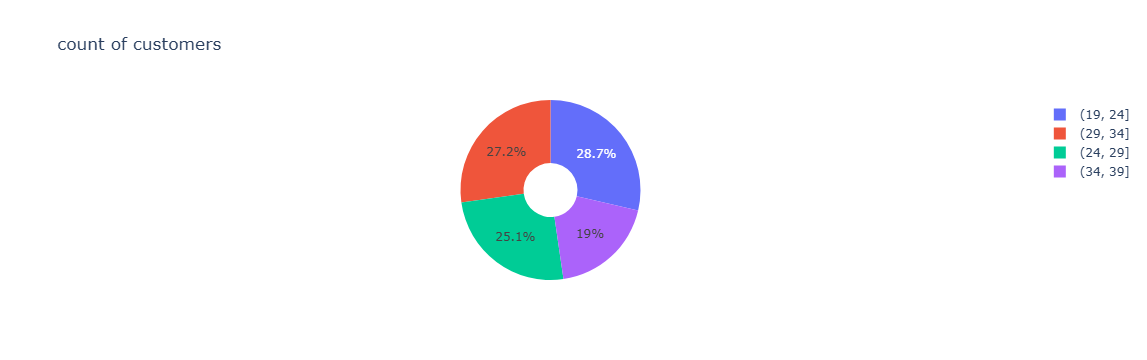

In [29]:
fig = px.pie(data_frame = q3 ,names = 'Age_Range',values = 'count',title = 'count of customers',hole = 0.3)             
fig.show()

#### 4) Find Count of each activity, represent it on bar chart


In [30]:
q4 = ca['Activity'].value_counts().reset_index()  # ye data frame mai convert krne ke liye use hota hai aur plotly mai dataframe krna zruri hai
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


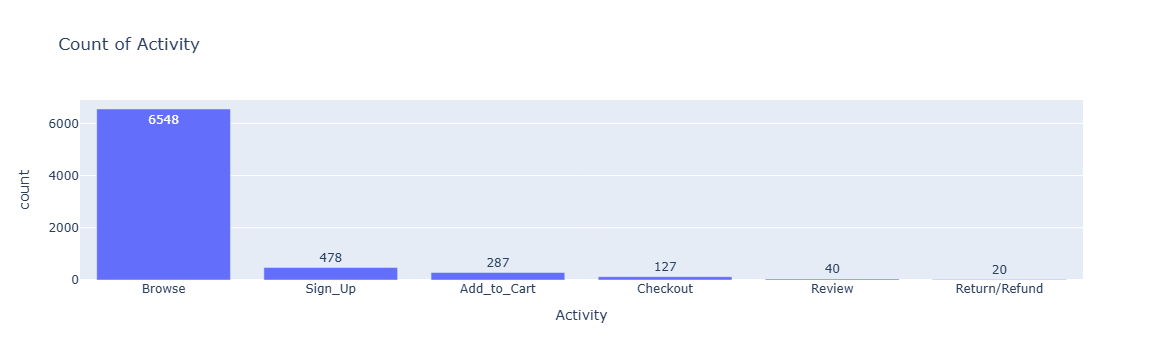

In [31]:
fig = px.bar(data_frame = q4, x = 'Activity', y = 'count',title = 'Count of Activity',
             text = 'count')
fig.show()

#### 5) Find order month wise total amount. Represent it on line chart.


In [32]:
orders.head()

,Order_id,Cust_ID,Amount,Payment_mode
0,ORD_71,CUS_545,2123.19,UPI
1,ORD_72,CUS_622,2788.02,Net Banking
2,ORD_73,CUS_418,3071.63,Credit_Card
3,ORD_74,CUS_360,5736.31,COD
4,ORD_75,CUS_714,1592.53,Debit Card


In [33]:
ca

,Cust_ID,Activity,Date
0,CUS_121,Sign_Up,2024-04-24
1,CUS_121,Browse,2024-04-27
2,CUS_121,Add_to_Cart,2024-04-27
3,CUS_121,Browse,2024-04-29
4,CUS_121,Browse,2024-04-30
...,...,...,...
7495,CUS_801,Browse,2024-11-16
7496,CUS_801,Browse,2024-11-20
7497,CUS_801,Browse,2024-11-23
7498,CUS_801,Browse,2024-11-26


In [34]:
ca['Date'] = pd.to_datetime(ca['Date'], format = '%Y-%m-%d')

In [35]:
ca['Month'] = ca['Date'].dt.month

In [36]:
orders

,Order_id,Cust_ID,Amount,Payment_mode
0,ORD_71,CUS_545,2123.19,UPI
1,ORD_72,CUS_622,2788.02,Net Banking
2,ORD_73,CUS_418,3071.63,Credit_Card
3,ORD_74,CUS_360,5736.31,COD
4,ORD_75,CUS_714,1592.53,Debit Card
...,...,...,...,...
122,ORD_193,CUS_512,5509.80,Credit_Card
123,ORD_194,CUS_292,6409.17,Credit_Card
124,ORD_195,CUS_372,6715.57,Credit_Card
125,ORD_196,CUS_795,4226.04,COD


In [37]:
ca_checkout = ca[ca['Activity'] == 'Checkout']
ca_checkout

,Cust_ID,Activity,Date,Month
6,CUS_121,Checkout,2024-05-05,5
71,CUS_127,Checkout,2024-06-16,6
92,CUS_129,Checkout,2025-04-02,4
162,CUS_135,Checkout,2024-08-02,8
206,CUS_139,Checkout,2024-10-12,10
...,...,...,...,...
7110,CUS_767,Checkout,2024-05-12,5
7157,CUS_771,Checkout,2024-07-26,7
7213,CUS_776,Checkout,2025-02-07,2
7259,CUS_780,Checkout,2025-03-23,3


In [38]:
ca_orders = pd.merge(orders,ca_checkout,on = 'Cust_ID',how = 'inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [39]:
q6 = ca_orders.groupby(ca_orders['Month'])['Amount'].sum().reset_index()
q6.head()

,Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46


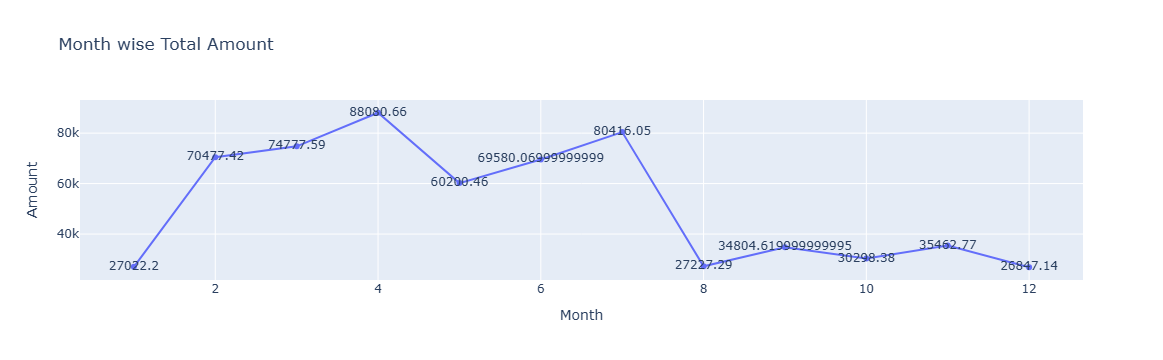

In [40]:
fig = px.line(data_frame = q6 ,x = 'Month',y = 'Amount',title = 'Month wise Total Amount',text = 'Amount')             
fig.show()

#### 6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.


In [41]:
sp.head()

,Plan_Var_ID,Plan_ID,Plan_name,Price,Duration
0,P1_1Y,P1,Silver,1200.0,1 Year
1,P1_6M,P1,Silver,720.0,6 Months
2,P2_1Y,P2,Gold,2400.0,1 Year
3,P2_6M,P2,Gold,1440.0,6 Months
4,P3_1Y,P3,Diamond,4800.0,1 Year


In [42]:
sub_plan = pd.merge(cs,sp,on = 'Plan_Var_ID',how = 'inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [43]:
q7 = sub_plan.groupby(['Plan_Var_ID'])['Price'].sum().reset_index()
q7

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


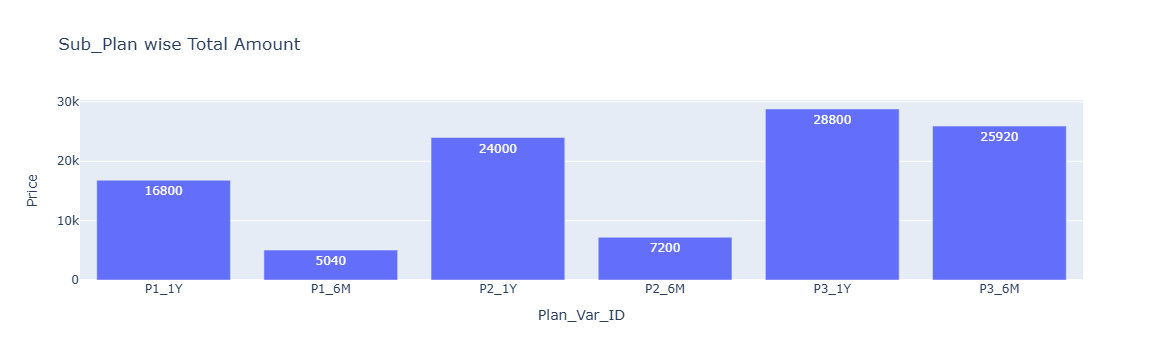

In [44]:
fig = px.bar(data_frame = q7 ,x = 'Plan_Var_ID',y = 'Price',title = 'Sub_Plan wise Total Amount',text = 'Price')             
fig.show()

#### 7) City wise find total amount

In [45]:
orders.shape

(127, 4)

In [46]:
city_wise = pd.merge(cb,orders,on = 'Cust_ID',how = 'inner')
city_wise

,Cust_ID,City,Age,Age_Range,Order_id,Amount,Payment_mode
0,CUS_121,Noida,30,"(29, 34]",ORD_83,3336.69,UPI
1,CUS_127,Delhi,24,"(19, 24]",ORD_172,6427.90,Credit_Card
2,CUS_129,Mumbai,20,"(19, 24]",ORD_97,8653.62,UPI
3,CUS_135,Kolkata,35,"(34, 39]",ORD_87,2551.37,Credit_Card
4,CUS_139,Noida,34,"(29, 34]",ORD_127,3290.14,UPI
...,...,...,...,...,...,...,...
122,CUS_767,Mumbai,37,"(34, 39]",ORD_180,5501.74,Credit_Card
123,CUS_771,Delhi,26,"(24, 29]",ORD_143,6356.73,Debit Card
124,CUS_776,Noida,22,"(19, 24]",ORD_117,4898.51,COD
125,CUS_780,Mumbai,22,"(19, 24]",ORD_89,2356.32,Net Banking


In [47]:
q8 = city_wise.groupby(['City'])['Amount'].sum().reset_index()
q8

,City,Amount
0,Chennai,96763.72
1,Delhi,147176.17
2,Kolkata,102185.83
3,Mumbai,120515.98
4,Noida,158552.95


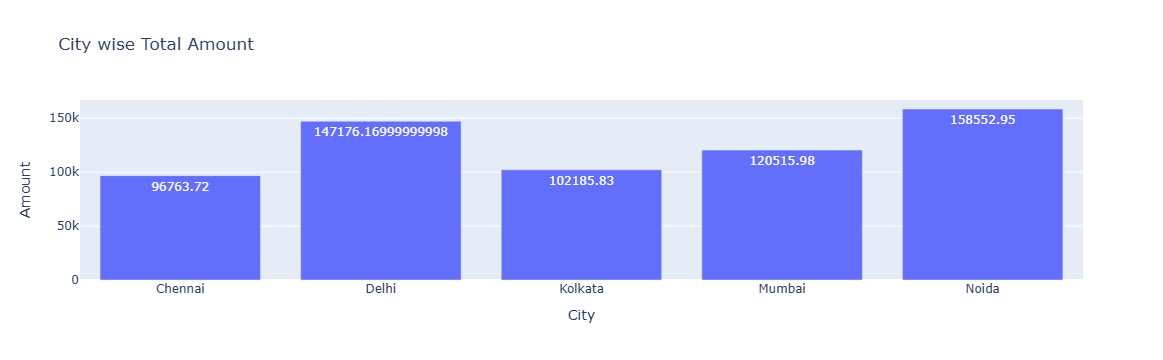

In [48]:
fig = px.bar(data_frame = q8 ,x = 'City',y = 'Amount',title = 'City wise Total Amount',text = 'Amount')             
fig.show()

#### 8) Find count of each payment mode, represent it on donut chart


In [49]:
q9 = orders['Payment_mode'].value_counts().reset_index()
q9

,Payment_mode,count
0,Net Banking,29
1,Debit Card,27
2,UPI,24
3,Credit_Card,24
4,COD,23


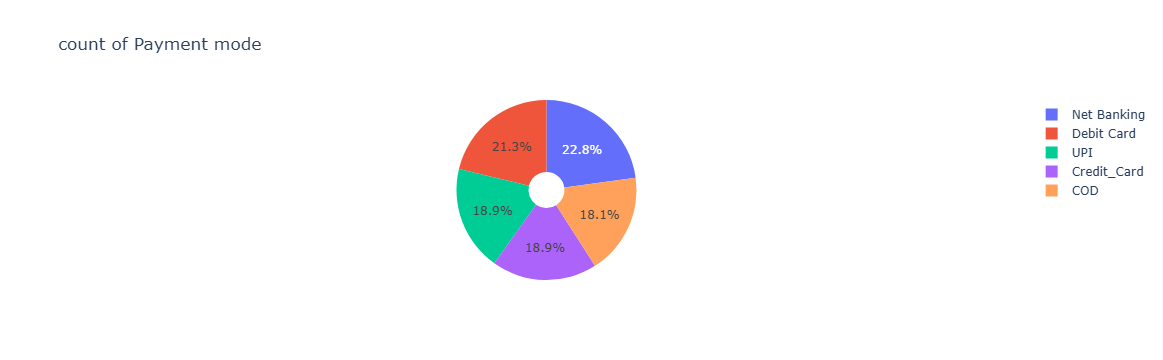

In [50]:
fig = px.pie(data_frame = q9 ,names = 'Payment_mode',values = 'count',title = 'count of Payment mode',hole = 0.2)             
fig.show()

#### 9) Represent Payment mode wise sum of amount on a strip plot


In [51]:
q9 = orders.groupby(['Payment_mode'])['Amount'].sum().reset_index()
q9

,Payment_mode,Amount
0,COD,115972.27
1,Credit_Card,127611.89
2,Debit Card,133145.11
3,Net Banking,137780.34
4,UPI,110685.04


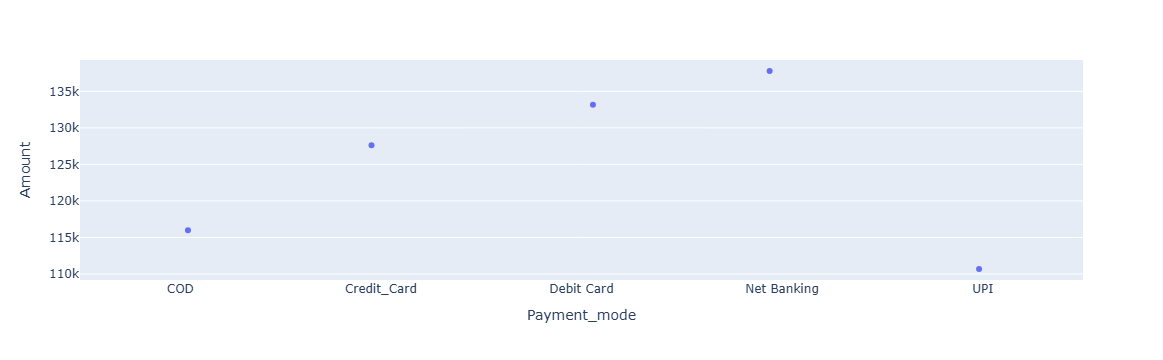

In [52]:
fig = px.strip(data_frame = q9,x = 'Payment_mode',y = 'Amount')
fig.show()

#### Funnel Analysis

#### 1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion


In [53]:
ca['Activity'].value_counts()

Activity
Browse           6548
Sign_Up           478
Add_to_Cart       287
Checkout          127
Review             40
Return/Refund      20
Name: count, dtype: int64

In [54]:
w1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name = 'count')
w1.head()

,Cust_ID,Activity,count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [55]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [56]:
funnel['prev_count'] = np.where(funnel['Activity']== 'Return/Refund',funnel['count'].shift(2),funnel['count'].shift(1))  


In [57]:
funnel

,Activity,count,prev_count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [58]:
funnel['%_conversion'] = round((funnel['count']/funnel['prev_count'])*100,2)
funnel.fillna(0,inplace = True)
funnel

,Activity,count,prev_count,%_conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [59]:
funnel['%_conversion'] = funnel['%_conversion'].apply(lambda x : str(x) +'%')
funnel
#funnel['%_conversion'] = funnel['%_conversion'].astype(str) + '%'

,Activity,count,prev_count,%_conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


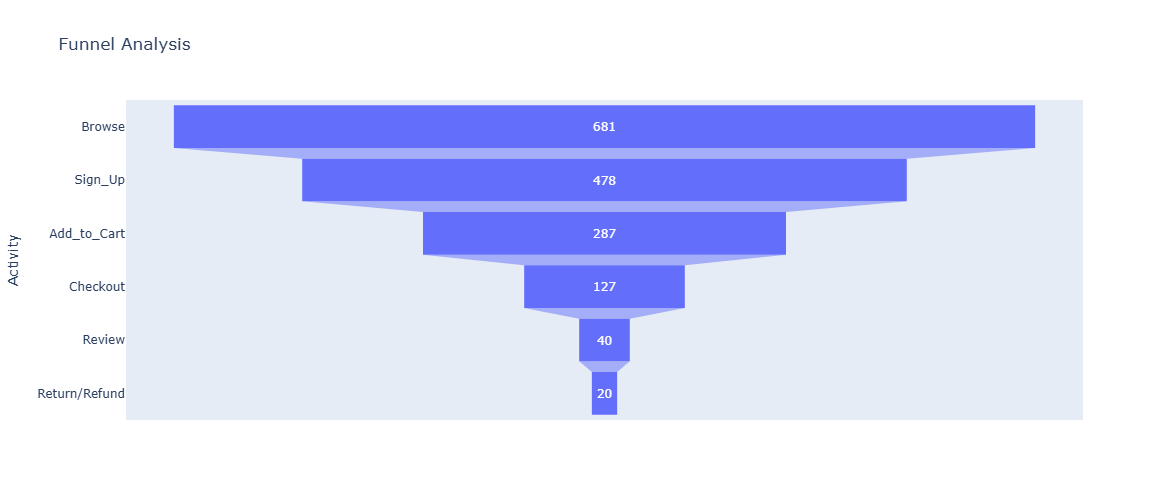

In [60]:
fig = px.funnel(data_frame = funnel ,x = 'count',y = 'Activity',title = 'Funnel Analysis ',height = 500,hover_data = '%_conversion')             
fig.show()

#### 2) Find Customer wise count of days to transition from one stage of funnel to the next stage


In [61]:
min_date = ca.groupby(['Cust_ID','Activity'])['Date'].min()
min_date

Cust_ID  Activity   
CUS_121  Add_to_Cart   2024-04-27
         Browse        2024-04-27
         Checkout      2024-05-05
         Sign_Up       2024-04-24
CUS_122  Browse        2025-07-12
                          ...    
CUS_798  Browse        2025-03-22
         Sign_Up       2025-03-19
CUS_799  Browse        2025-07-12
CUS_800  Browse        2024-02-25
CUS_801  Browse        2024-11-01
Name: Date, Length: 1633, dtype: datetime64[us]

In [62]:
pt1 = pd.pivot_table(data = ca ,index = ['Cust_ID'],columns = ['Activity'],values = 'Date',aggfunc = 'min') # NAT = Not At Time
pt1

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
...,...,...,...,...,...,...
CUS_797,NaT,2024-03-19,NaT,NaT,NaT,2024-03-15
CUS_798,NaT,2025-03-22,NaT,NaT,NaT,2025-03-19
CUS_799,NaT,2025-07-12,NaT,NaT,NaT,NaT


In [63]:
pt1['dd_browse_2_signup']= abs((pt1['Sign_Up'] - pt1['Browse']).dt.days)
pt1['dd_signup_2_Add_to_Cart']= abs((pt1['Add_to_Cart'] - pt1['Sign_Up']).dt.days)
pt1['dd_Add_to_Cart_2_checkout']= abs((pt1['Add_to_Cart'] - pt1['Checkout']).dt.days)
pt1['dd_checkout_2_review']= abs((pt1['Checkout'] - pt1['Review']).dt.days)
pt1['dd_checkout_2_Return/Refund']= abs((pt1['Checkout'] - pt1['Return/Refund']).dt.days)
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,dd_browse_2_signup,dd_signup_2_Add_to_Cart,dd_Add_to_Cart_2_checkout,dd_checkout_2_review,dd_checkout_2_Return/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN


#### 3) Find Avg_Days to transition from one Funnel stage to the next stage.


In [64]:
pt2 = pt1.iloc[:,-5:]
pt2

Activity,dd_browse_2_signup,dd_signup_2_Add_to_Cart,dd_Add_to_Cart_2_checkout,dd_checkout_2_review,dd_checkout_2_Return/Refund
Cust_ID,,,,,
CUS_121,3.0,3.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN
CUS_123,NaN,NaN,NaN,NaN,NaN
CUS_124,1.0,1.0,NaN,NaN,NaN
CUS_125,2.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...
CUS_797,4.0,NaN,NaN,NaN,NaN
CUS_798,3.0,NaN,NaN,NaN,NaN
CUS_799,NaN,NaN,NaN,NaN,NaN


In [65]:
tran_days = pt2.mean()
tran_days

Activity
dd_browse_2_signup              2.516736
dd_signup_2_Add_to_Cart         2.512195
dd_Add_to_Cart_2_checkout      14.425197
dd_checkout_2_review            2.625000
dd_checkout_2_Return/Refund     3.400000
dtype: float64

In [66]:
avg_days_to_tran = [0] + list(tran_days.values)
print(avg_days_to_tran)

[0, np.float64(2.51673640167364), np.float64(2.5121951219512195), np.float64(14.4251968503937), np.float64(2.625), np.float64(3.4)]


In [67]:
funnel['Avg_Days_2Tran'] = avg_days_to_tran
funnel['Avg_Days_2Tran'] = funnel['Avg_Days_2Tran'].apply(lambda x : round(x,2))
funnel

,Activity,count,prev_count,%_conversion,Avg_Days_2Tran
0,Browse,681,0.0,0.0%,0.00
1,Sign_Up,478,681.0,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04%,2.51
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


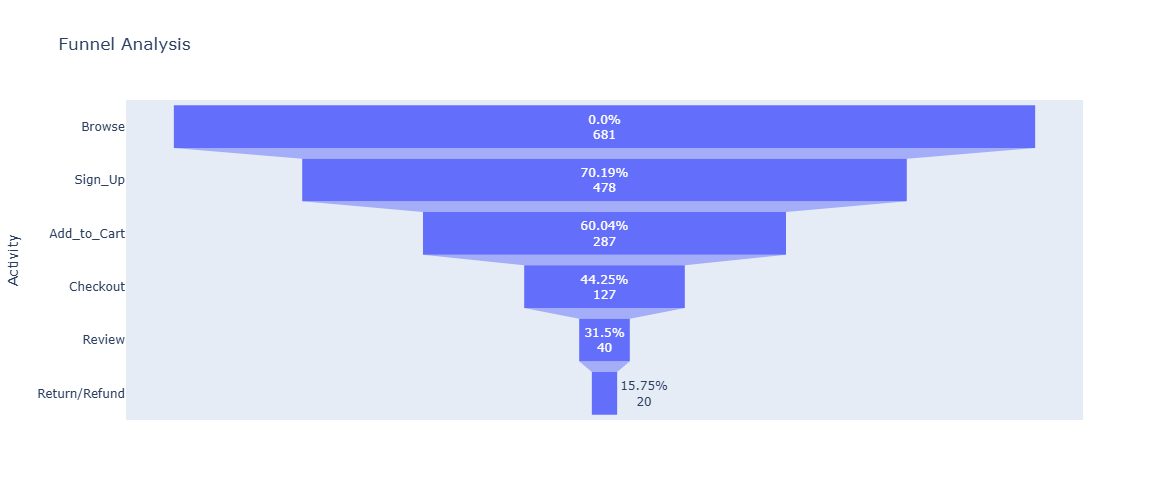

In [68]:
fig = px.funnel(data_frame = funnel ,x = 'count',y = 'Activity', text = '%_conversion',
                title = 'Funnel Analysis ',height = 500,hover_data = 'Avg_Days_2Tran')             
fig.show()

#### 4) Create function to analyse Funnel based on City.

In [69]:
def city_wise_funnel(city_name):
    city_df = cb[cb['City'] == city_name]
    return city_df

In [70]:
city_df = city_wise_funnel('Kolkata')
city_df.head()

,Cust_ID,City,Age,Age_Range
1,CUS_124,Kolkata,20,"(19, 24]"
2,CUS_125,Kolkata,24,"(19, 24]"
6,CUS_131,Kolkata,27,"(24, 29]"
8,CUS_135,Kolkata,35,"(34, 39]"
9,CUS_136,Kolkata,33,"(29, 34]"


In [71]:
city_ca = pd.merge(ca,city_df, on='Cust_ID', how='inner')
city_ca.head()

,Cust_ID,Activity,Date,Month,City,Age,Age_Range
0,CUS_124,Sign_Up,2025-01-05,1,Kolkata,20,"(19, 24]"
1,CUS_124,Browse,2025-01-06,1,Kolkata,20,"(19, 24]"
2,CUS_124,Add_to_Cart,2025-01-06,1,Kolkata,20,"(19, 24]"
3,CUS_124,Browse,2025-01-08,1,Kolkata,20,"(19, 24]"
4,CUS_124,Browse,2025-01-09,1,Kolkata,20,"(19, 24]"


In [72]:
city_ca['Activity'].value_counts()

Activity
Browse           865
Sign_Up           94
Add_to_Cart       54
Checkout          22
Review             5
Return/Refund      2
Name: count, dtype: int64

In [73]:
funnel = city_ca.groupby('Activity')['Cust_ID'].nunique()
funnel

Activity
Add_to_Cart      54
Browse           94
Checkout         22
Return/Refund     2
Review            5
Sign_Up          94
Name: Cust_ID, dtype: int64

In [74]:
ca['Activity'].unique()

<ArrowStringArray>
['Sign_Up', 'Browse', 'Add_to_Cart', 'Checkout', 'Review', 'Return/Refund']
Length: 6, dtype: str

In [75]:
funnel_order = ['Browse','Sign_Up','Add_to_Cart','Checkout','Review','Return/Refund']
funnel = funnel.reindex(funnel_order, fill_value=0)
funnel

Activity
Browse           94
Sign_Up          94
Add_to_Cart      54
Checkout         22
Review            5
Return/Refund     2
Name: Cust_ID, dtype: int64

In [76]:
conversion = (funnel / funnel.iloc[0] * 100).round(2)

funnel_df = pd.DataFrame({'Customers': funnel,'Conversion_%': conversion})
funnel_df ,

(               Customers  Conversion_%
 Activity                              
 Browse                94        100.00
 Sign_Up               94        100.00
 Add_to_Cart           54         57.45
 Checkout              22         23.40
 Review                 5          5.32
 Return/Refund          2          2.13,)

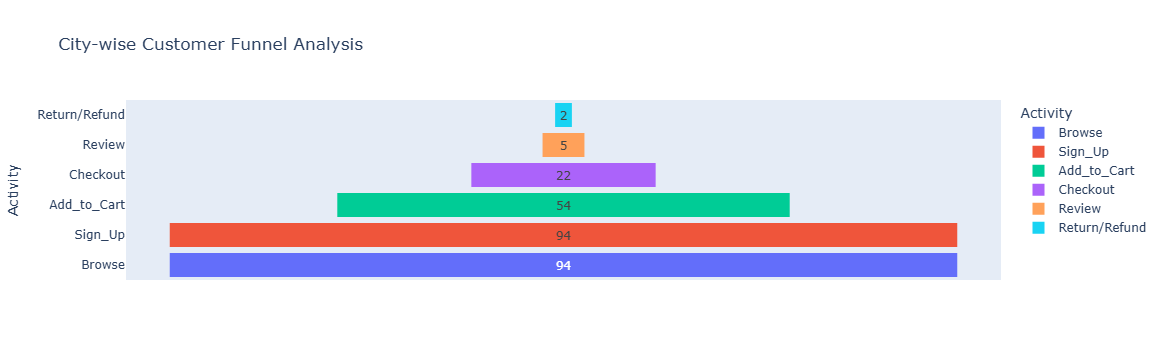

In [77]:
import plotly.express as px

fig = px.funnel(funnel_df.reset_index(),x='Customers',y='Activity',title='City-wise Customer Funnel Analysis',color='Activity')
fig.show()